# Inleiding

HBHavens exporteert resultaten naar databases (HRD, HLCD, config) voor gebruik in Riskeer. Per locatie geeft de gebruiker een verwijzing naar een HRD database op waar de resultaten in worden geschreven. 
Het HLCD bestand bevat een koppeling tussen normtrajecten ('Tracks') en HRD databases. Deze koppeling wordt bij het exporteren naar een nieuwe database niet aangepast aan de nieuwe database naam die is opgegeven in HBHavens. Hierdoor kan Riskeer de nieuwe database niet vinden en rekent Riskeer geen belastingen uit. 

De code van HBHavens is aangepast zodat voor iedere unieke opgegeven SQLite export database (in tabblad Exporteren), de koppeling aan de HLCD wordt toegevoegd. Dit gebeurt door het TrackID van opgegeven database op te zoeken, en voor deze TrackID in de HLCD de naam van de database te wijzigen naar de naam zoals opgegeven in HBHavens. De oorspronkelijke database naam wordt dus overschreven (omdat de TrackID uniek moet zijn).

Code wijzigingen:
- functie toegevoegd om de aanpassing in de SQLite db te maken: io.database.set_track_hrdfilename
- Regels toegevoegd aan model.export.export_output_to_database() om bovenstaande aan te voegen voor alle databases, als de optie "export_HLCD_and_config" aangevinkt is.



# Imports

In [15]:
import sys
import os
import shutil

owd = os.getcwd()
testdir = os.path.dirname(owd)
sys.path.append(testdir)
trunkdir = os.path.dirname(testdir)
sys.path.append(trunkdir)

import common
from hbhavens.core.models import MainModel
from hbhavens.core.geometry import extend_point_to_linestring

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

import warnings
warnings.simplefilter("ignore")

# Schematisatie

In [16]:
case = 'urk'
datadir = os.path.join(trunkdir, 'tests', 'data')
paths = {
    'harborarea': os.path.join(datadir, case, 'shapes', 'haventerrein.shp'),
    'breakwater': os.path.join(datadir, case, 'shapes', 'havendammen.shp'),
    'result_locations': os.path.join(datadir, case, 'shapes', 'uitvoerlocaties.shp'),
    'hrd': os.path.join(datadir, case, 'databases', 'WBI2017_IJsselmeer_7-2_v02_steunpunt.sqlite'),
    'config': os.path.join(datadir, case, 'databases', 'WBI2017_IJsselmeer_7-2_v02_steunpunt.config.sqlite'),
    'hlcd': os.path.join(datadir, 'hlcd.sqlite'),
}
trajecten = ['7-2']
bedlevel = -5.0
supportlocation = 'YM_3_7-2_ha02_00001'

# Run simple

In [19]:
tempdir = os.path.join(os.path.dirname(trunkdir),'temp')
if not os.path.exists(tempdir):
    os.mkdir(tempdir)

if os.path.isdir(os.path.join(tempdir, case, case)):
    shutil.rmtree(os.path.join(tempdir, case, case), ignore_errors=True)
if not os.path.exists(os.path.join(tempdir, case)):
    os.mkdir(os.path.join(tempdir, case))
if not os.path.exists(os.path.join(tempdir, case, case)):
    os.mkdir(os.path.join(tempdir, case, case))


In [20]:
model = MainModel()
model.project.settings['project']['name'] = case
model.project.settings['project']['user']['email'] = 'benit@hkv.nl'
model.project.settings['project']['user']['name'] = 'Matthijs Bénit'
model.project.save_as(os.path.join(tempdir, case, case + '.json'))

common.add_schematisation(model, paths=paths, supportlocationname=supportlocation, trajecten=trajecten, bedlevel=bedlevel)

model.project.settings['calculation_method']['method'] = 'simple'

# Calculate wave processes
model.simple_calculation.run_all(['Lokale golfgroei'])
model.simple_calculation.combinedresults.run(['Lokale golfgroei'])
model.simple_calculation.mainmodel.project.settings['simple']['finished'] = True
model.simple_calculation.save_results()


In [21]:
# #==============================================================================
# # Uncertainties
# #==============================================================================
model.modeluncertainties.add_result_locations()
model.modeluncertainties.load_modeluncertainties()

uncertainties = model.modeluncertainties.supportloc_unc.unstack()
uncertainties.index = [' '.join(vals) for vals in uncertainties.index]
model.modeluncertainties.table.loc[:, uncertainties.index] = uncertainties.values
model.modeluncertainties.save_tables()


# Export

In [22]:
# #==============================================================================
# # Export
# #==============================================================================
model.project.settings["export"]['HRD'] = os.path.join(tempdir, case, 'WBI2017_IJsselmeer_7-2_v02_steunpunt.sqlite')
model.project.settings["export"]["export_HLCD_and_config"] = True
shutil.copy2(paths['hrd'], os.path.join(tempdir, case))
shutil.copy2(paths['config'], os.path.join(tempdir, case))
shutil.copy2(paths['hlcd'], os.path.join(tempdir, case))

model.export.add_result_locations()

# Hier is de mogelijkheid om de namen aan de juiste conventie te laten voldoen. In de GUI gaat dit via een excel file
model.export.export_dataframe['Exportnaam'] = case + '_' + model.export.export_dataframe['Naam'] 
model.export.add_HLCD(os.path.join(tempdir, case, 'hlcd.sqlite'))
model.export.export_output_to_database()
model.project.settings['export']['export_succeeded'] = True


'c:\\Users\\Benit\\HB Havens R489\\temp\\urk\\WBI2017_IJsselmeer_7-2_v02_steunpunt.sqlite'

'c:\\Users\\Benit\\HB Havens R489\\temp\\urk\\WBI2017_IJsselmeer_7-2_v02_steunpunt.config.sqlite'

'c:\\Users\\Benit\\HB Havens R489\\temp\\urk\\hlcd.sqlite'

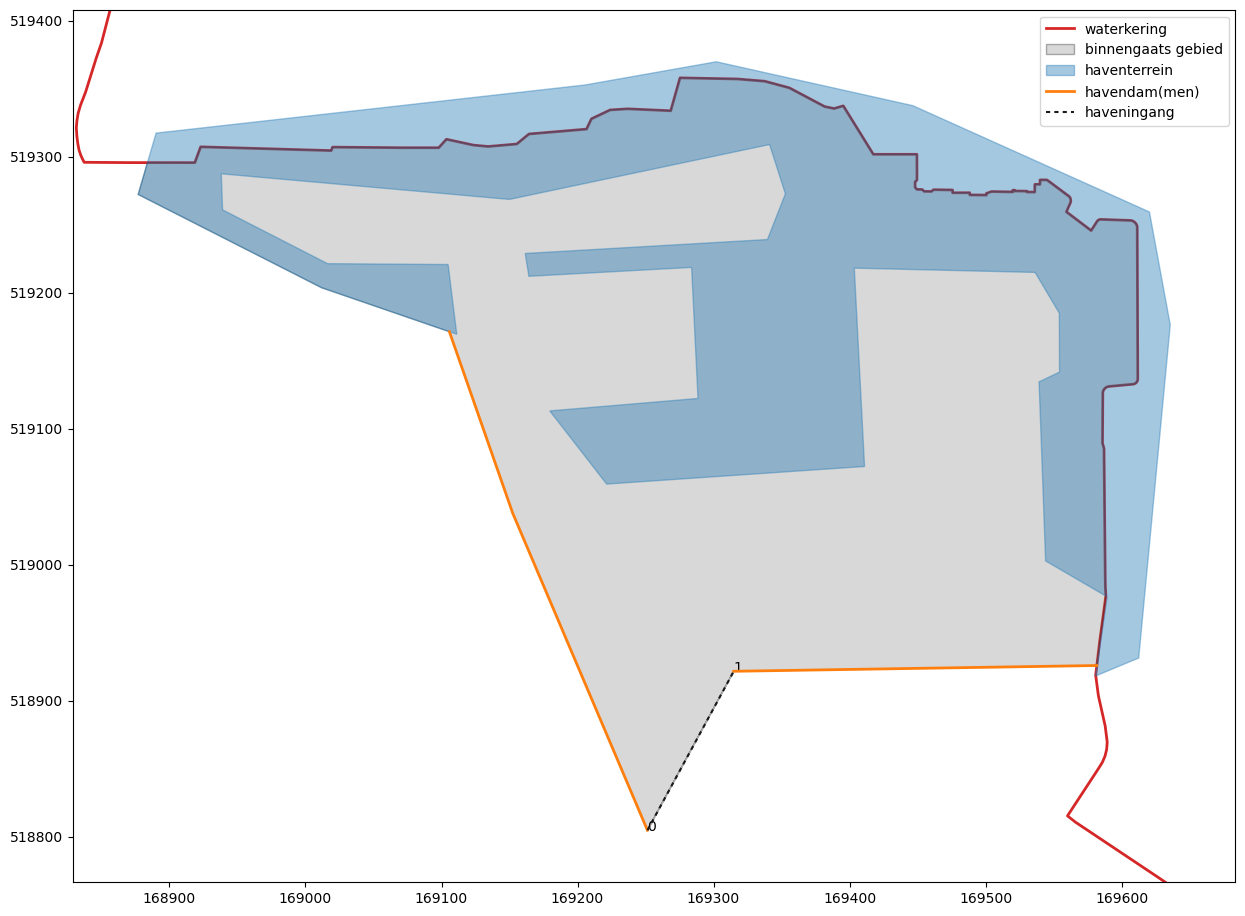

In [23]:
# Save results
model.project.save()
model.save_tables()
fig, ax = model.schematisation.plot_schematisation(buffer=10,locations=False)
